In [2]:
import pyautogui
import pandas as pd
import numpy as np
import datetime as dt
from importlib import reload
from source import select, plot

## Open formatted data

In [8]:
ds_disk.close()

In [3]:
import xarray as xr
reload(select)

#ifile = 'data/deployments/netcdf/k01_c_deploy.nc'
ifile = select.single_file()
ds_disk = xr.open_dataset(ifile)

ds_disk

<xarray.Dataset> Size: 83MB
Dimensions:  (TIME: 26456, CN: 29)
Coordinates:
  * TIME     (TIME) datetime64[ns] 212kB 2025-10-11T08:49:48 ... 2025-11-17T0...
  * CN       (CN) int64 232B 1 10 11 12 13 14 15 16 17 ... 28 29 3 4 5 6 7 8 9
Data variables: (12/33)
    CP       (TIME, CN) float64 6MB ...
    VE       (TIME, CN) float64 6MB ...
    VN       (TIME, CN) float64 6MB ...
    VU       (TIME, CN) float64 6MB ...
    VU2      (TIME, CN) float64 6MB ...
    A1       (TIME, CN) float64 6MB ...
    ...       ...
    SN       <U6 24B ...
    NB       int64 8B ...
    NC       int64 8B ...
    BD       float64 8B ...
    CS       float64 8B ...
    CY       <U3 12B ...

## Plot data

In [7]:
import matplotlib.pyplot as plt
import datetime as dt
from source import plot
reload(plot)

xlim = [dt.timedelta(days=-15, hours=-24), dt.timedelta(days=-15, hours=-1)]

fig = plot.plot_data(
    ds_disk,
    plot_type=1,
    corr_threshold=40,
    clim=0.8,
    xlim=xlim,
    ylim=(0,30),
    y_mode='range',
    datefmt='%H:%M',
)

# First/last timestamps
time0 = pd.to_datetime(ds_disk['TIME'].values[0])
time1 = pd.to_datetime(ds_disk['TIME'].values[-1])

# Duration
duration = time1 - time0
total_minutes = int(duration.total_seconds() // 60)

days, rem = divmod(total_minutes, 24 * 60)
hours, minutes = divmod(rem, 60)

if days > 0:
    duration_str = f'{days}d {hours}h {minutes}min'
elif hours > 0:
    duration_str = f'{hours}h {minutes}min'
else:
    duration_str = f'{minutes} min'

# Main title
date_str = time0.strftime('%Y-%m-%d %H:%M:%S')
title = f'{date_str}  -  {duration_str}'

# Filename
filename = ifile.rpartition('/')[-1]
filename_wo_ext = ifile.rpartition('/')[-1].split('.')[0]

# Titles
title_height = 0.95
fig.suptitle(title, fontsize=15, y=title_height)
fig.text(0.5, title_height-0.035, filename, ha='center', va='top', fontsize=10)

display(fig)

KeyError: "No variable named 'A5'. Variables on the dataset include ['CP', 'VE', 'VN', 'VU', 'VU2', ..., 'NB', 'NC', 'BD', 'CS', 'CY']"

In [12]:
fig_width, fig_height = fig.get_size_inches()

# Top edge of all subplots in figure coordinates
subplot_top = max(ax.get_position().y1 for ax in fig.axes)

print('Figure height:', fig_height)
print('Top subplot:', subplot_top)
print('Title y:', title_height)
print('Distance subplot → title:', (title_height - subplot_top) * fig_height, 'in')

Figure height: 8.0
Top subplot: 0.88
Title y: 0.95
Distance subplot → title: 0.5599999999999996 in


## Report figure

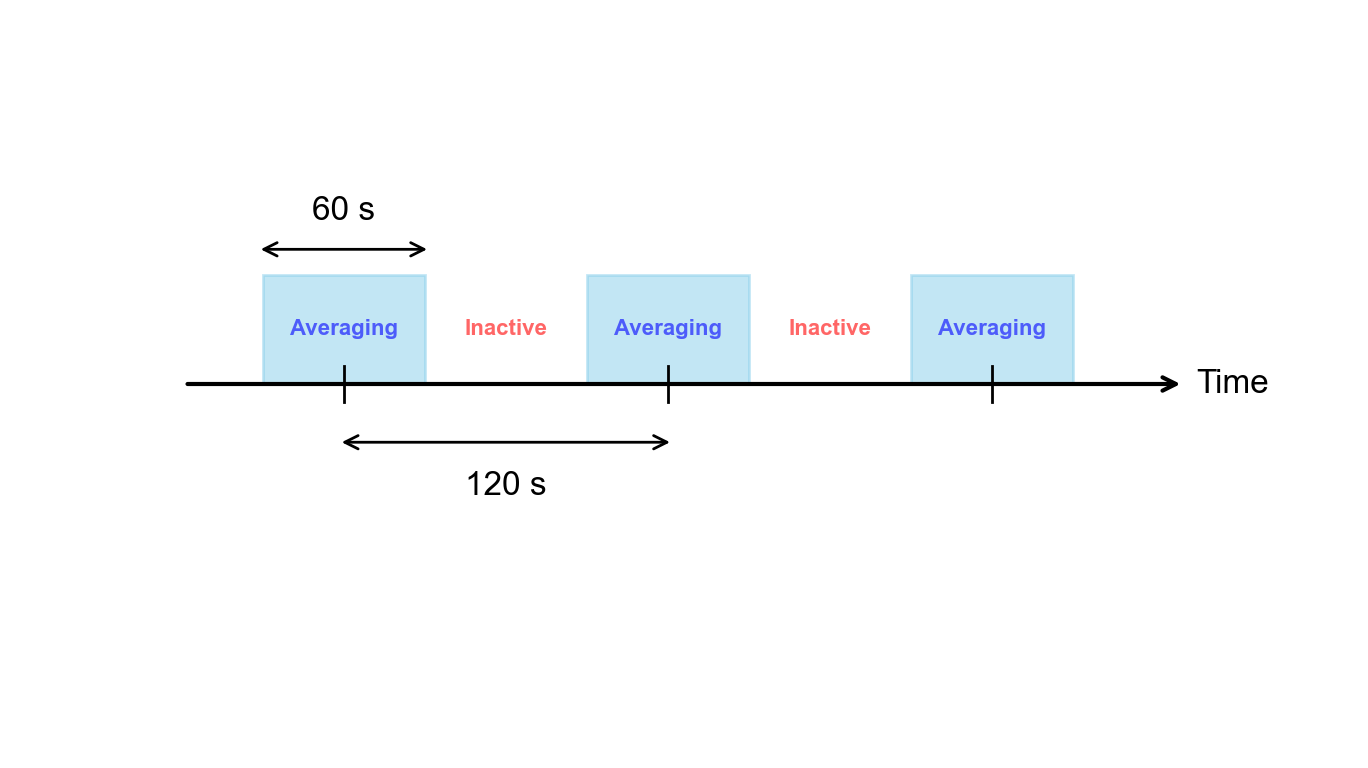

In [206]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches

# --- Customization Parameters ---

# Font settings
font_size = 12
font_family = "Arial"
active_label_fontsize = 8
inactive_label_fontsize = 8

# Tick and arrow settings
tick_length = 0.1
arrow_linewidth = 1.5
arrow_offset = 0.024
time_arrowhead_offset = 0.03

# Layout dimensions
rect_width = 0.5
rect_height = 0.3
line_offset_above_rect = 0.07
label_offset_above_line = 0.06
line_offset_below_axis = 0.16
label_offset_below_line = 0.08
x_axis_left_pad = 0.5
x_axis_right_pad = 0.6

# Colors
rect_color = 'skyblue'
rect_alpha = 0.5
active_text_color = 'blue'
inactive_text_color = 'red'
tick_color = 'black'
axis_arrow_color = 'black'

# Labels
averaging_label = "60 s"
measurement_label = "120 s"
time_label = "Time"
active_label = "Averaging"
inactive_label = "Inactive"

# Number of intervals
num_ticks = 3
tick_positions = list(range(num_ticks))

# Apply font settings
plt.rcParams['font.size'] = font_size
plt.rcParams["font.family"] = font_family

# --- Derived Positions ---
rect_base_y = 0
averaging_line_y = rect_base_y + rect_height + line_offset_above_rect
averaging_label_y = averaging_line_y + label_offset_above_line
measurement_line_y = -line_offset_below_axis
measurement_label_y = measurement_line_y - label_offset_below_line
text_inside_rect_y = rect_base_y + rect_height / 2

# --- Plot Setup ---
fig, ax = plt.subplots(figsize=(7, 4), dpi=200)

# === Rectangles (ACTIVE periods) ===
for x in tick_positions:
    rect = patches.Rectangle(
        (x - rect_width / 2, rect_base_y), rect_width, rect_height,
        linewidth=1, edgecolor=rect_color, facecolor=rect_color, alpha=rect_alpha
    )
    ax.add_patch(rect)

# === Averaging Interval Line & Label ===
x0 = tick_positions[0]
ax.annotate(
    "", 
    xy=(x0 - rect_width / 2 - arrow_offset, averaging_line_y),
    xytext=(x0 + rect_width / 2 + arrow_offset, averaging_line_y),
    arrowprops=dict(arrowstyle='<->')
)
ax.text(x0, averaging_label_y, averaging_label, ha='center', va='bottom')

# === Measurement Interval Line & Label ===
x1 = tick_positions[1]
ax.annotate(
    "", 
    xy=(x0 - arrow_offset, measurement_line_y), 
    xytext=(x1 + arrow_offset, measurement_line_y),
    arrowprops=dict(arrowstyle='<->')
)
ax.text((x0 + x1) / 2, measurement_label_y, measurement_label, ha='center', va='top')

# === ACTIVE / INACTIVE Labels ===
for x in tick_positions:
    ax.text(x, text_inside_rect_y, active_label, fontsize=active_label_fontsize, fontweight='bold',
            alpha=0.6, color=active_text_color, va='center', ha='center')
for x in tick_positions[:-1]:
    ax.text(x + 0.5, text_inside_rect_y, inactive_label, fontsize=inactive_label_fontsize, fontweight='bold',
            alpha=0.6, color=inactive_text_color, va='center', ha='center')

# === Hide All Spines ===
for spine in ax.spines.values():
    spine.set_visible(False)

# === X-Axis Arrow ===
arrow_start = tick_positions[0] - x_axis_left_pad
arrow_end = tick_positions[-1] + x_axis_right_pad
ax.annotate(
    "", 
    xy=(arrow_end, 0), 
    xytext=(arrow_start, 0),
    arrowprops=dict(arrowstyle='->', linewidth=arrow_linewidth, color=axis_arrow_color)
)
ax.text(arrow_end + time_arrowhead_offset, 0, time_label, va='center')

# === Custom Tick Marks ===
for x in tick_positions:
    ax.plot([x, x], [-tick_length / 2, tick_length / 2], color=tick_color, lw=1)

# === Final Layout ===
ax.set_xticks([])
ax.set_yticks([])
ax.set_xlim(arrow_start - 0.5, arrow_end + 0.5)
ax.set_ylim(-1, 1)
plt.tight_layout()
plt.show()


In [199]:
fig.savefig(f'plots/averaging_interval.png', bbox_inches='tight')